<a href="https://colab.research.google.com/github/mr-ragv/news_category/blob/main/News_Categorization_Using_Your_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Import the required libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import spacy
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.preprocessing import LabelEncoder

import tensorflow as tf
import tensorflow_hub as hub
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


# Phase 1. Data Acquisition & Initial Load

## Load the dataset

*This step begins by loading the dataset and narrowing it down to the most relevant features, such as category, headline and short_description, for the classification task.*

In [ ]:
# Load the uploaded CSV dataset
df_original = pd.read_csv("/content/news_category_dataset.csv")

# Keep the same three fields used by the original project.
df_original = df_original[['category', 'headline', 'short_description']].copy()

# Handle missing text fields before combining them later.
df_original['headline'] = df_original['headline'].fillna('')
df_original['short_description'] = df_original['short_description'].fillna('')
df_original['category'] = df_original['category'].astype(str).str.strip()

# Remove rows without a usable headline or category.
df_original = df_original[
    (df_original['headline'].str.strip() != '') &
    (df_original['category'].str.strip() != '')
].reset_index(drop=True)

print("Loaded dataset shape:", df_original.shape)


Loaded dataset shape: (103131, 3)


In [ ]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


## Explore and analysis the dataset

*Before diving into data preprocessing and model building, it was important to first understand the structure and content of the dataset. I started by using df.head() to preview a few sample entries and df.info() to inspect the data types and check for any missing values. To get a sense of the dataset’s scale, I used df.shape, and then explored the distribution of news categories with df['category'].value_counts(). These categories serve as the target labels for the classification task. Based on the results, the dataset contains 42 distinct news categories.*

In [ ]:
print(df_original.head())
print('\n')
print(df_original.info())
print('\n')
print(df_original.shape)
print('\n')
print(df_original['category'].value_counts())

    category                                           headline  \
0  U.S. NEWS  Over 4 Million Americans Roll Up Sleeves For O...   
1  U.S. NEWS  American Airlines Flyer Charged, Banned For Li...   
2     COMEDY  23 Of The Funniest Tweets About Cats And Dogs ...   
3  PARENTING  The Funniest Tweets From Parents This Week (Se...   
4  U.S. NEWS  Woman Who Called Cops On Black Bird-Watcher Lo...   

                                   short_description  
0  Health experts said it is too early to predict...  
1  He was subdued by passengers and crew when he ...  
2  "Until you have a dog you don't understand wha...  
3  "Accidentally put grown-up toothpaste on my to...  
4  Amy Cooper accused investment firm Franklin Te...  


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103131 entries, 0 to 103130
Data columns (total 3 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   category           103131 non-null  object
 1   headli

*To keep the project focused, efficient, and more balanced, I decided not to use the entire dataset. The original dataset contains 42 categories with a wide variation in the number of articles per category. Some categories are heavily overrepresented, while others have very few samples.*

*To address this and reduce computational overhead, I filtered the dataset to include only the top 15 most frequent categories. This subset still offers a diverse range of topics and provides a solid foundation for building and evaluating a classification model, without the noise and imbalance introduced by rare classes.*

*This approach allows for:*

*- Faster processing and experimentation*

*- A more balanced class distribution*

*- Easier interpretation of results*

*All further preprocessing, feature extraction, and modeling will be based on this filtered subset.*

In [ ]:
# Get the top 15 most frequent categories
top_15_categories = df_original['category'].value_counts().nlargest(15).index

# Filter the dataset to include only those categories
df = df_original[df_original['category'].isin(top_15_categories)].copy()

#  Check the new shape and distribution
print(df.shape)
print(df['category'].value_counts())


(84010, 3)
category
POLITICS          31314
ENTERTAINMENT     12866
HEALTHY LIVING     3966
QUEER VOICES       3930
THE WORLDPOST      3664
SPORTS             3437
COMEDY             3420
BLACK VOICES       3331
WORLD NEWS         3299
PARENTS            2680
WOMEN              2552
BUSINESS           2495
CRIME              2385
WEIRD NEWS         2363
MEDIA              2308
Name: count, dtype: int64


In [ ]:
df

*To create a richer and more informative textual representation of each news article, I combined the headline and short_description fields into a single column called news_description. This consolidated text provides more context, which can help improve the model’s ability to accurately understand and classify the content. After combining, the original headline and short_description columns were dropped to keep the dataset clean and focused.*

In [ ]:
# Combine headline and short description, as in the original notebook.
# Missing descriptions have already been filled with empty strings.
df['news_description'] = (
    df['headline'].fillna('').astype(str) + ' ' +
    df['short_description'].fillna('').astype(str)
).str.strip()
df = df.drop(columns=['headline', 'short_description'])


## Check for the missing value

In [ ]:
# Check missing values percentage
missing_percent = (df.isnull().sum() / len(df)) * 100
print(missing_percent)

category            0.0
news_description    0.0
dtype: float64


*To ensure the dataset is clean and ready for analysis, I checked for missing values in each column. Based on the output, all columns showed 0% missing values, indicating that the dataset is complete. Therefore, no additional handling for missing data is needed at this stage.*

In [ ]:
df

,category,news_description
2,COMEDY,23 Of The Funniest Tweets About Cats And Dogs ...
7,WORLD NEWS,Puerto Ricans Desperate For Water After Hurric...
9,WORLD NEWS,Biden At UN To Call Russian War An Affront To ...
10,WORLD NEWS,World Cup Captains Want To Wear Rainbow Armban...
11,WORLD NEWS,Man Sets Himself On Fire In Apparent Protest O...
...,...,...
103124,MEDIA,Rolling Stone Will Retract UVA Story: REPORT
103125,ENTERTAINMENT,'SNL' Begs Michael Keaton To Reprise Batman
103126,QUEER VOICES,Florida Bakery Faces Threats After Refusing To...
103127,ENTERTAINMENT,Norman Reedus Shoots Pete Davidson With An Arr...


# Phase 2. Dataset Exploration & Visualization

## Visualize Dataset Features

#### 1. Category Distribution: Plot the distribution of articles across the 15 categories

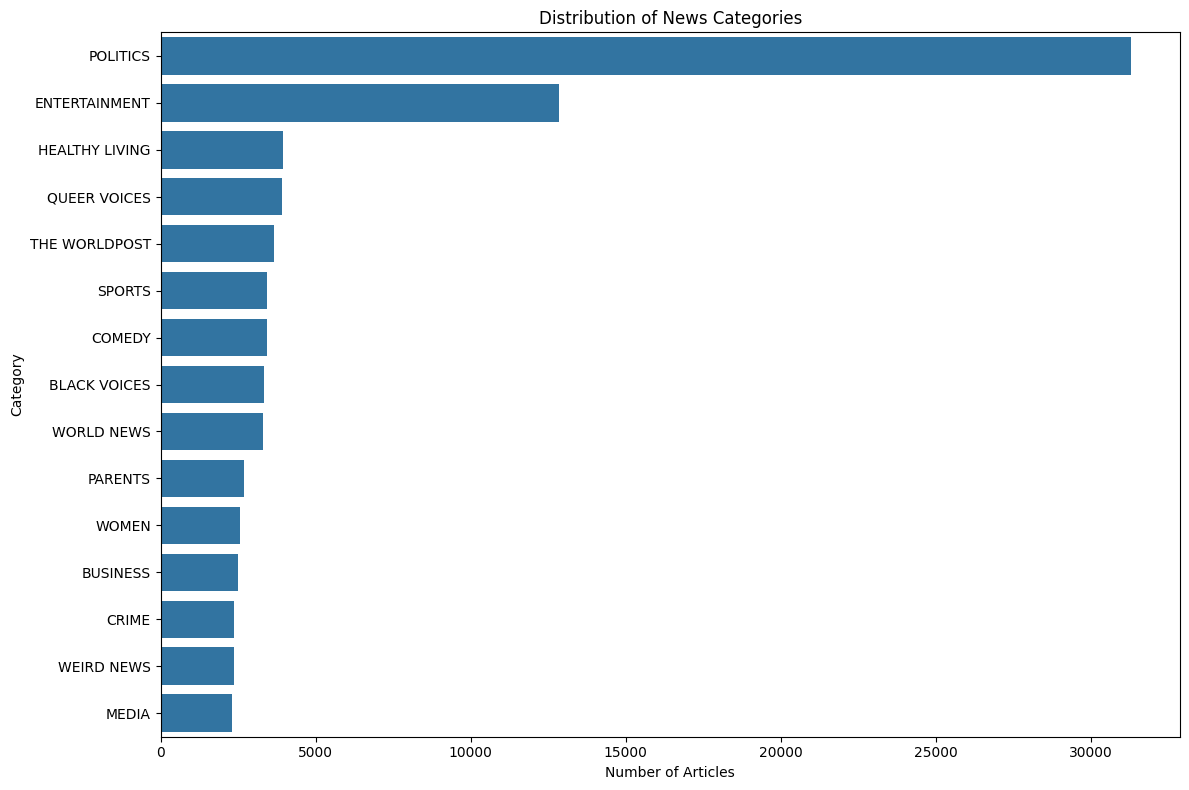

In [ ]:
plt.figure(figsize=(12, 8))
sns.countplot(y='category', data=df, order=df['category'].value_counts().index)
plt.title('Distribution of News Categories')
plt.xlabel('Number of Articles')
plt.ylabel('Category')
plt.tight_layout()
plt.show()

*The bar chart above displays the distribution of news categories in the dataset, where the X-axis represents the number of articles and the Y-axis lists the category names.*

#### 2. Text Length Distribution: Analyze the length of the combined text column (number of words or characters)

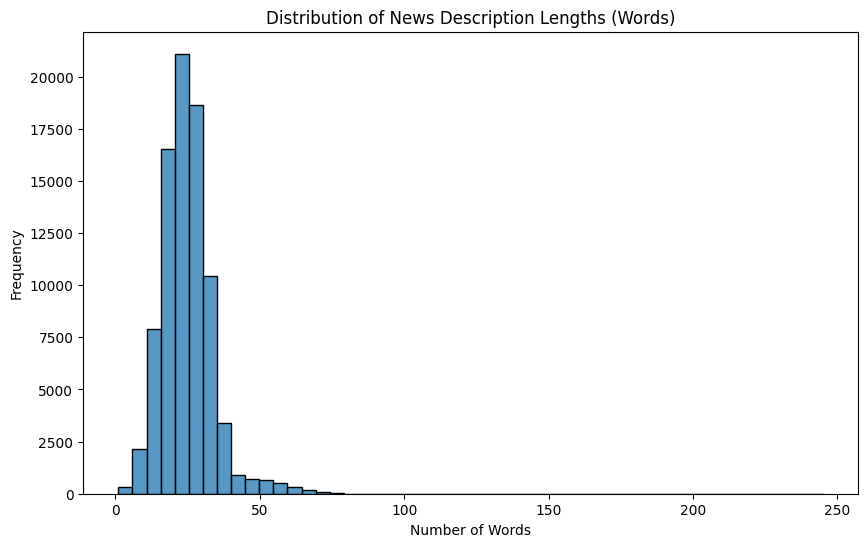

In [ ]:
df['news_desc_length'] = df['news_description'].apply(lambda x: len(x.split()))
plt.figure(figsize=(10, 6))
sns.histplot(df['news_desc_length'], bins=50)
plt.title('Distribution of News Description Lengths (Words)')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

*The histogram above illustrates the distribution of news description lengths measured by word count. The X-axis represents the number of words, and the Y-axis indicates the frequency of articles with that length.*

**Understanding Our Text Data and Choosing the Right Embedding**

Looking at the first chart, we can see that the dataset is focused on the top 15 most common news categories, with Politics, Wellness, and Entertainment leading the way. This gives us a solid range of topics while keeping the scope manageable for our project.

The second chart tells us something important about the text itself, most news descriptions are short, with the majority falling between 10 and 50 words. This means we’re working with concise, to-the-point summaries rather than lengthy articles.

So, here is how does this affect our choice of embedding methods.

- **TF-IDF** is a good starting point for short texts since it captures the most important words without worrying about word order.

- **SpaCy’s word embeddings** provide a bit more meaning by using pre-trained vectors, but because they treat each word individually, they might miss the bigger picture in short sentences.

- **Universal Sentence Encoder (USE)** is especially well-suited for this kind of data. It looks at the whole sentence and understands the context, even when the input is brief.

In short, because our data is compact and focused, methods like USE that consider sentence-level meaning are likely to perform best.

#### 3. Word Clouds (Pre-cleaning): Generate a word cloud for the entire dataset to see prominent words before cleaning.

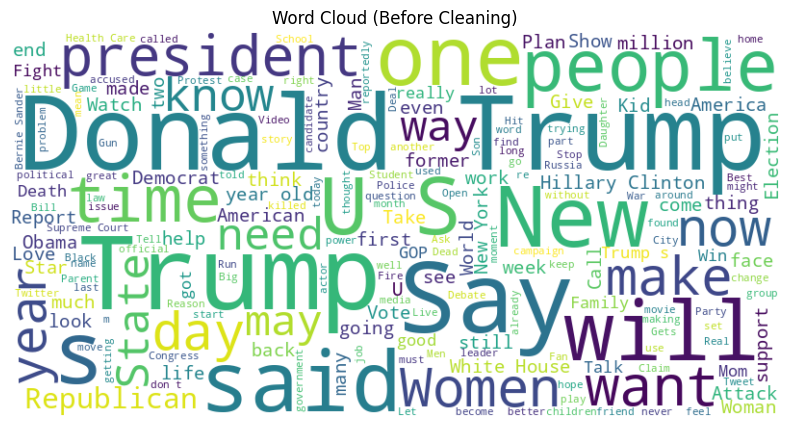

In [ ]:
from wordcloud import WordCloud
news_corpus = " ".join(df['news_description'].tolist())
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(news_corpus)
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud (Before Cleaning)')
plt.show()

*The word cloud above visualizes the most frequently occurring words across all news descriptions before any text preprocessing is applied. While it helps highlight dominant terms like "people", "new", "make", and "life", it also reveals several types of noise that should be addressed during the cleaning process.*

# Phase 3. Text Cleaning & Preprocessing

## Prepare text for cleaning

*This code sets up key NLP resources for text preprocessing, such as stopword removal, lemmatization, and loading a pre-trained spaCy model.*

In [ ]:
# Load the same large English SpaCy model used by the original notebook.
# Download it automatically if this is a fresh Colab runtime.
try:
    nlp = spacy.load("en_core_web_lg")
except OSError:
    !python -m spacy download en_core_web_lg
    nlp = spacy.load("en_core_web_lg")

print("SpaCy model loaded. Vector width:", nlp.vocab.vectors_length)


SpaCy model loaded. Vector width: 300


## Approach 1: Basic Rule-Based / Regex Cleaning

*This function performs fundamental text cleaning using regular expressions (regex) and NLTK-based preprocessing. The goal is to standardize and simplify the news descriptions before feeding them into machine learning or NLP models.*

In [ ]:
def clean_news_description_basic(news_description):
    news_description = news_description.lower() # Lowercasing
    news_description = re.sub(r'http\S+|www\S+|https\S+', '', news_description, flags=re.MULTILINE) # Remove URLs
    news_description = re.sub(r'\S*@\S*\s?', '', news_description) # Remove emails
    news_description = re.sub(r'#\S+', '', news_description) # Remove hashtags
    news_description = re.sub(r'[^\w\s]', '', news_description) # Remove punctuation and special characters
    news_description = re.sub(r'\d+', '', news_description) # Remove numbers
    news_description = re.sub(r'\s+', ' ', news_description).strip() # Remove extra spaces

    # Tokenization & Stop word removal & Lemmatization
    tokens = news_description.split()
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens] # Use lemmatizer
    return " ".join(tokens)

df['news_description_cleaned_basic'] = df['news_description'].apply(clean_news_description_basic)
print("Basic Cleaning Sample:")
print(df[['news_description', 'news_description_cleaned_basic']].head(100))

Basic Cleaning Sample:
                                      news_description  \
2    23 Of The Funniest Tweets About Cats And Dogs ...   
7    Puerto Ricans Desperate For Water After Hurric...   
9    Biden At UN To Call Russian War An Affront To ...   
10   World Cup Captains Want To Wear Rainbow Armban...   
11   Man Sets Himself On Fire In Apparent Protest O...   
..                                                 ...   
155  Jared Kushner Blasts 'Nasty Troll' Chrissy Tei...   
156  'Kimmel' Host Nikki Glaser Absolutely Goes The...   
157  Mar-A-Lago Search Affidavit: Trump Was Insecur...   
158  Donald Trump's Truth Social Reportedly Faces M...   
159  FINISH HIM: Fighting Kangaroo Pulls Wild Move ...   

                        news_description_cleaned_basic  
2    funniest tweet cat dog week sept dog dont unde...  
7    puerto ricans desperate water hurricane fionas...  
9    biden un call russian war affront body charter...  
10   world cup captain want wear rainbow armband qa.

## Approach 2: SpaCy Pipeline Cleaning

*This method leverages SpaCy, a powerful NLP library, to perform more linguistically informed text preprocessing. It goes beyond simple rule-based cleaning by using part-of-speech tagging, lemmatization, and built-in stopword and punctuation filtering.*

In [ ]:
def clean_news_description_spacy(news_description, nlp_model):
    doc = nlp_model(news_description.lower()) # Process news_description with SpaCy, lowercase
    tokens = []
    for token in doc:
        # Get the tokens which are not punctuation, not whitespace, not a stop word, and specific POS tags
        if not token.is_punct and not token.is_space and not token.is_stop:
            if token.pos_ in ['NOUN', 'VERB', 'ADJ', 'PROPN']:
                tokens.append(token.lemma_)
    return " ".join(tokens)

# Apply SpaCy cleaning
df['news_description_cleaned_spacy'] = df['news_description'].apply(lambda x: clean_news_description_spacy(x, nlp))
print("\nSpaCy Cleaning Sample:")
print(df[['news_description', 'news_description_cleaned_spacy']].head(100))


SpaCy Cleaning Sample:
                                      news_description  \
2    23 Of The Funniest Tweets About Cats And Dogs ...   
7    Puerto Ricans Desperate For Water After Hurric...   
9    Biden At UN To Call Russian War An Affront To ...   
10   World Cup Captains Want To Wear Rainbow Armban...   
11   Man Sets Himself On Fire In Apparent Protest O...   
..                                                 ...   
155  Jared Kushner Blasts 'Nasty Troll' Chrissy Tei...   
156  'Kimmel' Host Nikki Glaser Absolutely Goes The...   
157  Mar-A-Lago Search Affidavit: Trump Was Insecur...   
158  Donald Trump's Truth Social Reportedly Faces M...   
159  FINISH HIM: Fighting Kangaroo Pulls Wild Move ...   

                        news_description_cleaned_spacy  
2     funny tweet cat dog week sept dog understand eat  
7    puerto rican desperate water hurricane fiona r...  
9    biden un russian war affront body charter whit...  
10   world cup captain want wear rainbow armband qa

## Final cleaning choice for downstream tasks

*After exploring both cleaning methods, I’ve decided to move forward with the news_description_cleaned_spacy version for the rest of this project. Compared to the basic rule-based approach, the SpaCy pipeline offers a more meaningful and refined representation of the text. It helps keep the important parts, like key nouns, verbs, and proper names, while removing unnecessary noise like stopwords, punctuation, and filler words. I believe this approach provides cleaner and more informative input, which should be more helpful for training an accurate classification model.*

# Phase 4: Implementation of Three Word Embedding Methods

## 1. Prepare Data for Modeling

### Label Encoding (Convert string categories into numerical labels)

*The purpose of this method is to convert string categories into numerical labels.*

In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df['category_id'] = label_encoder.fit_transform(df['category'])
num_classes = len(label_encoder.classes_)
print(f"\nNumber of categories: {num_classes}")
print(f"Mapping: {list(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))}")


Number of categories: 15
Mapping: [('BLACK VOICES', np.int64(0)), ('BUSINESS', np.int64(1)), ('COMEDY', np.int64(2)), ('CRIME', np.int64(3)), ('ENTERTAINMENT', np.int64(4)), ('HEALTHY LIVING', np.int64(5)), ('MEDIA', np.int64(6)), ('PARENTS', np.int64(7)), ('POLITICS', np.int64(8)), ('QUEER VOICES', np.int64(9)), ('SPORTS', np.int64(10)), ('THE WORLDPOST', np.int64(11)), ('WEIRD NEWS', np.int64(12)), ('WOMEN', np.int64(13)), ('WORLD NEWS', np.int64(14))]


### Split the dataset into training and testing sets

*This code defines what will be the features and lable for our classification task.*

In [ ]:
X = df['news_description_cleaned_spacy']
y = df['category_id']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

Train samples: 67208, Test samples: 16802


### Label Transformation & Class Imbalance Handling

*The labels were converted to one-hot format so the model can handle multi-class classification properly.*

*To deal with category imbalance, I also calculated class weights. This helps the model pay more attention to less frequent categories during training, improving overall fairness and accuracy.*

In [ ]:
# Convert labels to one-hot encoding for Keras
y_train_one_hot = to_categorical(y_train, num_classes=num_classes)
y_test_one_hot = to_categorical(y_test, num_classes=num_classes)

# Use class weights to handle imbalance
from sklearn.utils import class_weight
class_weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights_dict = dict(enumerate(class_weights))

## 2. Implement Three Word Embedding Methods

### Embedding Method 1: TF-IDF

*I used TF-IDF to convert the text into numerical features, capturing the importance of each word and bigram across the dataset. To keep things efficient, I limited the vocabulary to the top 5,000 features.*

*Then, I built a simple neural network with two hidden layers and dropout to prevent overfitting. The model uses categorical crossentropy for multi-class classification and is optimized with the Adam optimizer.*

In [ ]:
# TF-IDF features for the deployable model.
# Use the notebook's basic cleaning column so the hosted API does not need
# to install the very large en_core_web_lg model just to predict a headline.
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    dtype=np.float32
)
X_train_tfidf_sparse = tfidf_vectorizer.fit_transform(
    df.loc[X_train.index, 'news_description_cleaned_basic']
)
X_test_tfidf_sparse = tfidf_vectorizer.transform(
    df.loc[X_test.index, 'news_description_cleaned_basic']
)

# The original Dense neural-network architecture expects dense numeric inputs.
# Convert in float32 to reduce memory use; Colab T4 is recommended.
X_train_tfidf = X_train_tfidf_sparse.toarray().astype(np.float32)
X_test_tfidf = X_test_tfidf_sparse.toarray().astype(np.float32)

print("TF-IDF train shape:", X_train_tfidf.shape)
print("TF-IDF test shape:", X_test_tfidf.shape)

# Keep the same TF-IDF neural-network architecture from the original notebook.
model_tfidf = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_tfidf.shape[1],)),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])
model_tfidf.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


TF-IDF train shape: (67208, 5000)
TF-IDF test shape: (16802, 5000)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Embedding Method 2: Pre-trained Static Word Embeddings (SpaCy's Built-in Vectors)

*For this approach, I used SpaCy’s built-in word vectors to create document embeddings. Each news description is turned into a single vector by averaging the embeddings of meaningful tokens (ignoring stopwords, punctuation, and empty tokens).*

*These averaged vectors were then passed into a neural network similar to the one used in the TF-IDF approach. The model includes dropout layers for regularization and uses categorical crossentropy loss for multi-class classification.*

*This method captures more semantic meaning than TF-IDF, as the vectors are based on how words relate to each other in context.*

In [ ]:
# Function to get document embeddings by averaging SpaCy token vectors
def get_spacy_doc_embedding(text, nlp_model):
    doc = nlp_model(text)
    # Get the tokens that don't have vectors and are not empty
    vectors = [token.vector for token in doc if token.has_vector and not token.is_punct and not token.is_space]
    if vectors:
        return np.mean(vectors, axis=0)
    else:
        return np.zeros(nlp_model.vocab.vectors.shape[1])

# Apply to training and testing data
X_train_spacy_emb = np.array([get_spacy_doc_embedding(text, nlp) for text in X_train])
X_test_spacy_emb = np.array([get_spacy_doc_embedding(text, nlp) for text in X_test])

print(f"\nSpaCy Embeddings Shape (Train): {X_train_spacy_emb.shape}")

# Define a model for SpaCy Embeddings
model_spacy_emb = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_spacy_emb.shape[1],)),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])
model_spacy_emb.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])


SpaCy Embeddings Shape (Train): (67208, 300)


### Embedding Method 3: Universal Sentence Encoder (USE)

*For this approach, I used the Universal Sentence Encoder (USE) from TensorFlow Hub to generate contextual embeddings for each entry in the news_description column, which combines both the article's headline and short description. This gives the model a more complete view of each article’s content.*

*USE creates high-quality, sentence-level embeddings that capture the semantic meaning of the entire text, making it especially effective for inputs that are short but rich in information.*

*The resulting embeddings were fed into a neural network with dropout layers to prevent overfitting. Like the other models, it uses categorical crossentropy loss and the Adam optimizer for multi-class classification.*

*This method is powerful because it provides rich, context-aware representations with minimal preprocessing.*

In [ ]:
print("\n--- Setting up Contextual Embeddings (Universal Sentence Encoder) ---")
embed = hub.load("https://tfhub.dev/google/universal-sentence-encoder/4")
print("Universal Sentence Encoder model loaded.")

# Function to get embeddings for a list of texts
def get_use_embeddings(texts, encoder_model, batch_size=64):
    embeddings = []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        batch_embeddings = encoder_model(tf.constant(batch)).numpy()
        embeddings.append(batch_embeddings)
    return np.vstack(embeddings)

# Apply to training and testing data
X_train_use_emb = get_use_embeddings(X_train.tolist(), embed)
X_test_use_emb = get_use_embeddings(X_test.tolist(), embed)

print(f"Universal Sentence Encoder Embeddings Shape (Train): {X_train_use_emb.shape}")
print(f"Universal Sentence Encoder Embeddings Shape (Test): {X_test_use_emb.shape}")

# Define a model for USE Embeddings
model_use_emb = Sequential([
    Dense(256, activation='relu', input_shape=(X_train_use_emb.shape[1],)),
    Dropout(0.5),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')
])
model_use_emb.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])


--- Setting up Contextual Embeddings (Universal Sentence Encoder) ---
Universal Sentence Encoder model loaded.
Universal Sentence Encoder Embeddings Shape (Train): (67208, 512)
Universal Sentence Encoder Embeddings Shape (Test): (16802, 512)


# Phase 5: Model Training & Evaluation

This phase involves training the models and collecting performance data.

## 1. Train TF-IDF Model:

*To train the model using TF-IDF features, I ran the neural network for 10 epochs with a batch size of 32. I also used 10% of the training data for validation, which helped monitor performance during training. Since the dataset has some imbalance across categories, I applied class weights to give fair attention to underrepresented classes.*

*After training, I evaluated the model on the test set to check its final accuracy.*

*Next, I generated predictions and calculated key performance metrics, including precision, recall, and F1-score (macro averaged). The macro F1 score gives a balanced view across all categories, treating each class equally regardless of how many samples it has.*

*This evaluation helps measure not just how accurate the model is, but also how fairly it performs across different news categories.*

In [ ]:
print("\n--- Training TF-IDF Model ---")
history_tfidf = model_tfidf.fit(
    X_train_tfidf, y_train_one_hot,
    epochs=10,
    batch_size=256,
    validation_split=0.1,
    verbose=1,
    class_weight=class_weights_dict
)
loss_tfidf, accuracy_tfidf = model_tfidf.evaluate(X_test_tfidf, y_test_one_hot, verbose=0)
print(f"TF-IDF Test Accuracy: {accuracy_tfidf:.4f}")

# Make the predictions and get the full metrics
y_pred_tfidf_probs = model_tfidf.predict(X_test_tfidf)
y_pred_tfidf = np.argmax(y_pred_tfidf_probs, axis=1)
precision_tfidf, recall_tfidf, f1_tfidf, _ = precision_recall_fscore_support(y_test, y_pred_tfidf, average='macro', zero_division=0)
print(f"TF-IDF F1-Macro: {f1_tfidf:.4f}")


--- Training TF-IDF Model ---
Epoch 1/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 10s 23ms/step - accuracy: 0.4288 - loss: 2.1055 - val_accuracy: 0.6051 - val_loss: 1.3730
Epoch 2/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5906 - loss: 1.3011 - val_accuracy: 0.6106 - val_loss: 1.2747
Epoch 3/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.6328 - loss: 1.0856 - val_accuracy: 0.6121 - val_loss: 1.2604
Epoch 4/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6562 - loss: 0.9557 - val_accuracy: 0.6219 - val_loss: 1.2344
Epoch 5/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6771 - loss: 0.8575 - val_accuracy: 0.6118 - val_loss: 1.2608
Epoch 6/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6928 - loss: 0.7708 - val_accuracy: 0.6133 - val_loss: 1.2641
Epoch 7/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7106 - loss: 0.6871 - val_accuracy: 0.6120 - val_loss: 1.2832
Epoch 8/10
237/237 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7291 

## 2. Train SpaCy Embeddings Model:

*I trained the neural network using the document-level vectors generated from SpaCy’s pre-trained word embeddings. The model was trained for 10 epochs with a batch size of 32, and 10% of the training data was used for validation. To address class imbalance, I included class weights during training.*

*Once training was complete, I evaluated the model on the test set to get the overall accuracy.*

*To better understand the model’s performance across all categories, I generated predictions and calculated the macro-averaged precision, recall, and F1-score. This provides a balanced view of how well the model performs across both frequent and rare categories.*

In [ ]:
print("\n--- Training SpaCy Embeddings Model ---")
history_spacy_emb = model_spacy_emb.fit(
    X_train_spacy_emb, y_train_one_hot,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1,
    class_weight=class_weights_dict
)
loss_spacy_emb, accuracy_spacy_emb = model_spacy_emb.evaluate(X_test_spacy_emb, y_test_one_hot, verbose=0)
print(f"SpaCy Embeddings Test Accuracy: {accuracy_spacy_emb:.4f}")

# Make the predictions and get the full metrics
y_pred_spacy_emb_probs = model_spacy_emb.predict(X_test_spacy_emb)
y_pred_spacy_emb = np.argmax(y_pred_spacy_emb_probs, axis=1)
precision_spacy_emb, recall_spacy_emb, f1_spacy_emb, _ = precision_recall_fscore_support(y_test, y_pred_spacy_emb, average='macro', zero_division=0)
print(f"SpaCy Embeddings F1-Macro: {f1_spacy_emb:.4f}")


--- Training SpaCy Embeddings Model ---
Epoch 1/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.4468 - loss: 1.6776 - val_accuracy: 0.5496 - val_loss: 1.3850
Epoch 2/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.5209 - loss: 1.4238 - val_accuracy: 0.5328 - val_loss: 1.3977
Epoch 3/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5385 - loss: 1.3593 - val_accuracy: 0.5724 - val_loss: 1.2997
Epoch 4/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.5461 - loss: 1.3196 - val_accuracy: 0.5510 - val_loss: 1.3241
Epoch 5/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5501 - loss: 1.2857 - val_accuracy: 0.5734 - val_loss: 1.2442
Epoch 6/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.5542 - loss: 1.2578 - val_accuracy: 0.5691 - val_loss: 1.2571
Epoch 7/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5567 - loss: 1.2330 - val_accuracy: 0.5763 - val_loss: 1.2287
Epoch 8/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 6s 3m

## 3. Train Universal Sentence Encoder Model:

*For this approach, I trained a neural network using embeddings generated from the Universal Sentence Encoder (USE), which captures the overall meaning of each news_description. The model was trained for 10 epochs with a batch size of 32, and 10% of the training data was reserved for validation. I also used class weights to balance the influence of each category.*

*After training, I evaluated the model on the test set to check its accuracy.*

*To get a more complete picture of the model’s performance, I predicted the test labels and calculated the macro-averaged precision, recall, and F1-score. This ensures that performance is measured fairly across both common and less frequent categories.*

In [ ]:
print("\n--- Training Universal Sentence Encoder Model ---")
history_use_emb = model_use_emb.fit(
    X_train_use_emb, y_train_one_hot,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1,
    class_weight=class_weights_dict
)
loss_use_emb, accuracy_use_emb = model_use_emb.evaluate(X_test_use_emb, y_test_one_hot, verbose=0)
print(f"Universal Sentence Encoder Test Accuracy: {accuracy_use_emb:.4f}")

# Make the predictions and get the full metrics
y_pred_use_emb_probs = model_use_emb.predict(X_test_use_emb)
y_pred_use_emb = np.argmax(y_pred_use_emb_probs, axis=1)
precision_use_emb, recall_use_emb, f1_use_emb, _ = precision_recall_fscore_support(y_test, y_pred_use_emb, average='macro', zero_division=0)
print(f"Universal Sentence Encoder F1-Macro: {f1_use_emb:.4f}")


--- Training Universal Sentence Encoder Model ---
Epoch 1/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - accuracy: 0.5045 - loss: 1.5134 - val_accuracy: 0.6184 - val_loss: 1.1706
Epoch 2/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5672 - loss: 1.2610 - val_accuracy: 0.5862 - val_loss: 1.2513
Epoch 3/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5786 - loss: 1.2168 - val_accuracy: 0.5950 - val_loss: 1.1928
Epoch 4/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5863 - loss: 1.1766 - val_accuracy: 0.6023 - val_loss: 1.1850
Epoch 5/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.5916 - loss: 1.1450 - val_accuracy: 0.6166 - val_loss: 1.1282
Epoch 6/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.5965 - loss: 1.1163 - val_accuracy: 0.5773 - val_loss: 1.2455
Epoch 7/10
1891/1891 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6009 - loss: 1.0953 - val_accuracy: 0.5914 - val_loss: 1.1842
Epoch 8/10
1891/1891 ━━━━━━━━━━━━━━━━━

# Phase 6: Comparison of the Results of Word Embedding Methods

## Summary to compare the key metrics for all three models

*To evaluate and compare the performance of all three embedding approaches, I created a summary table that presents the key metrics: Accuracy, F1-Macro, Precision-Macro, and Recall-Macro.*

*This comparison helps highlight not only how well each model performs overall (accuracy), but also how balanced its predictions are across all categories (macro-averaged metrics). These scores give a clearer picture of which embedding method provides the best combination of performance and fairness.*

In [ ]:
results_summary = pd.DataFrame({
        'Embedding Method': ['TF-IDF', 'SpaCy Embeddings', 'USE'],
        'Accuracy': [accuracy_tfidf, accuracy_spacy_emb, accuracy_use_emb],
        'F1-Macro': [f1_tfidf, f1_spacy_emb, f1_use_emb],
        'Precision-Macro': [precision_tfidf, precision_spacy_emb, precision_use_emb],
        'Recall-Macro': [recall_tfidf, recall_spacy_emb, recall_use_emb]
    })
print("\n--- Model Performance Comparison ---")
print(results_summary)


--- Model Performance Comparison ---
   Embedding Method  Accuracy  F1-Macro  Precision-Macro  Recall-Macro
0            TF-IDF  0.619926  0.546721         0.517051      0.600030
1  SpaCy Embeddings  0.575348  0.535265         0.505339      0.623553
2               USE  0.617784  0.568982         0.530509      0.649960


### Results Summary & Comparison

*The table above presents the performance of all three models based on different embedding methods: TF-IDF, SpaCy embeddings, and the Universal Sentence Encoder (USE). The evaluation is based on four key metrics: Accuracy, F1-Macro, Precision-Macro, and Recall-Macro.*

*From the results,*

***USE*** achieved the highest overall accuracy (0.7110) and also led in F1-Macro and Recall-Macro, suggesting it performs best at correctly classifying across all categories, including the less frequent ones.*

***TF-IDF*** came in second, with solid performance across all metrics and slightly higher Precision-Macro than SpaCy, showing that traditional approaches can still be strong baselines.*

***SpaCy embeddings***, while more semantically rich than TF-IDF, performed slightly lower in all metrics, possibly due to averaging losing some context from shorter texts.*

*Overall, ***USE*** demonstrated the most balanced and consistent performance, making it the most effective embedding method for this multi-class news classification task.*

## Detailed Performance Analysis (Results Visualization - Confusion Matrix)

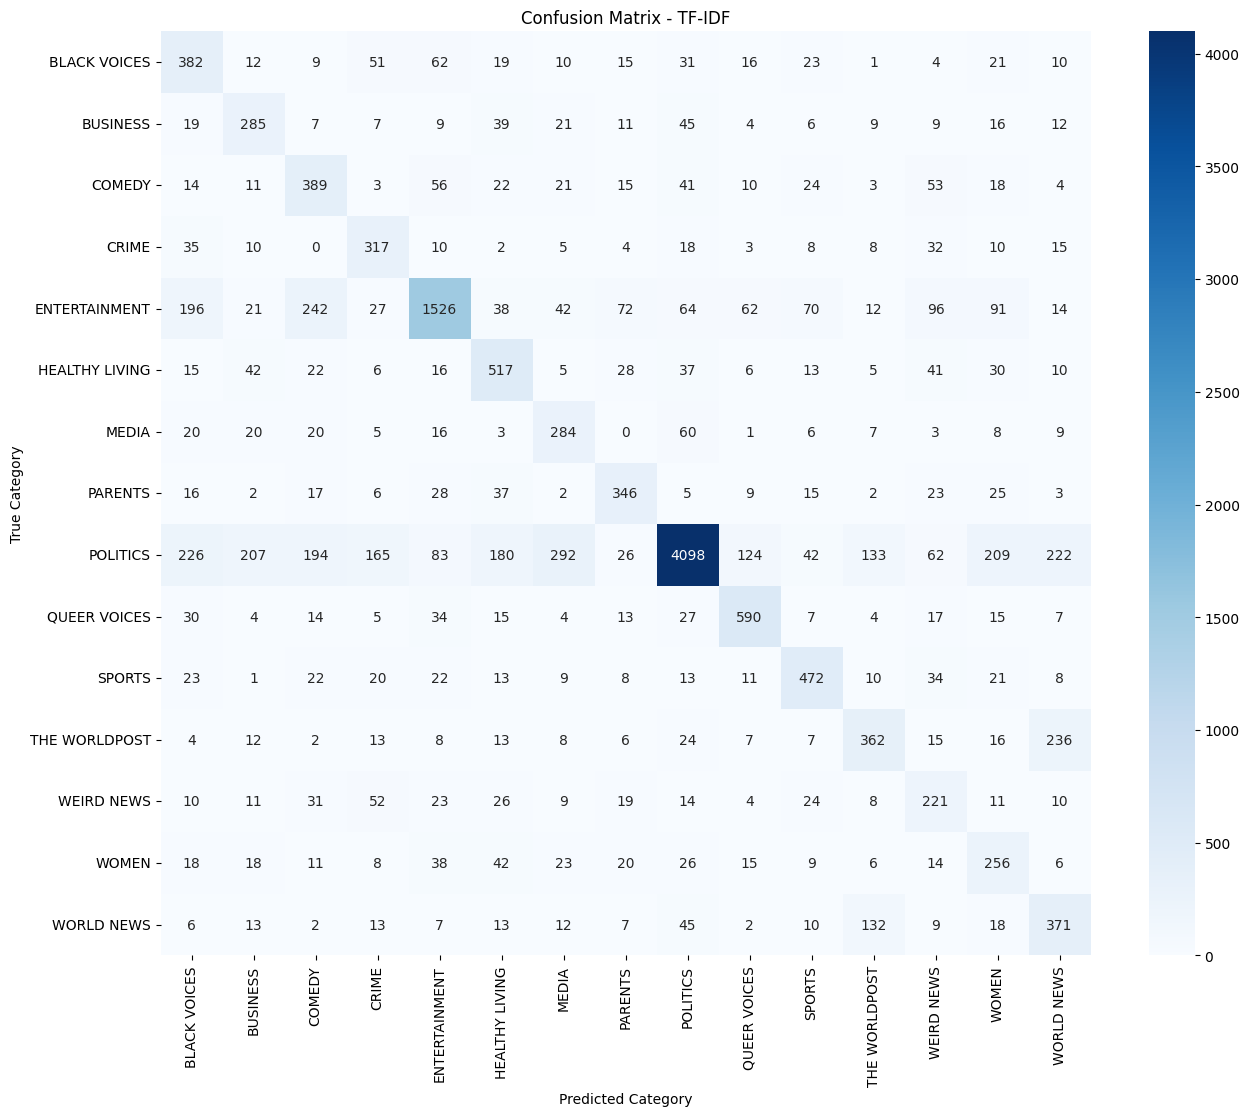

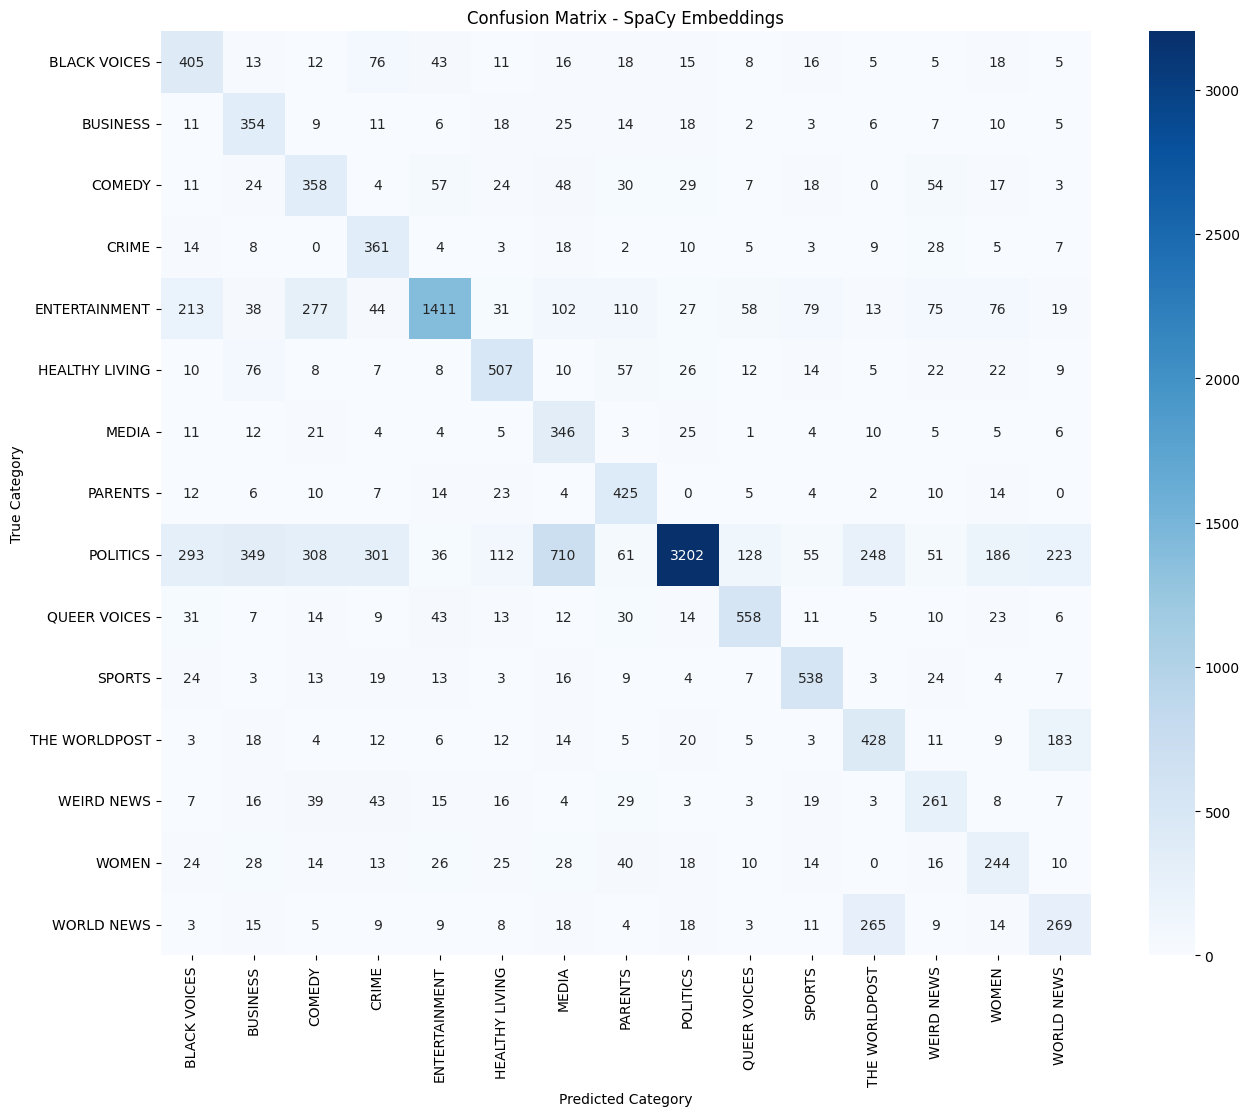

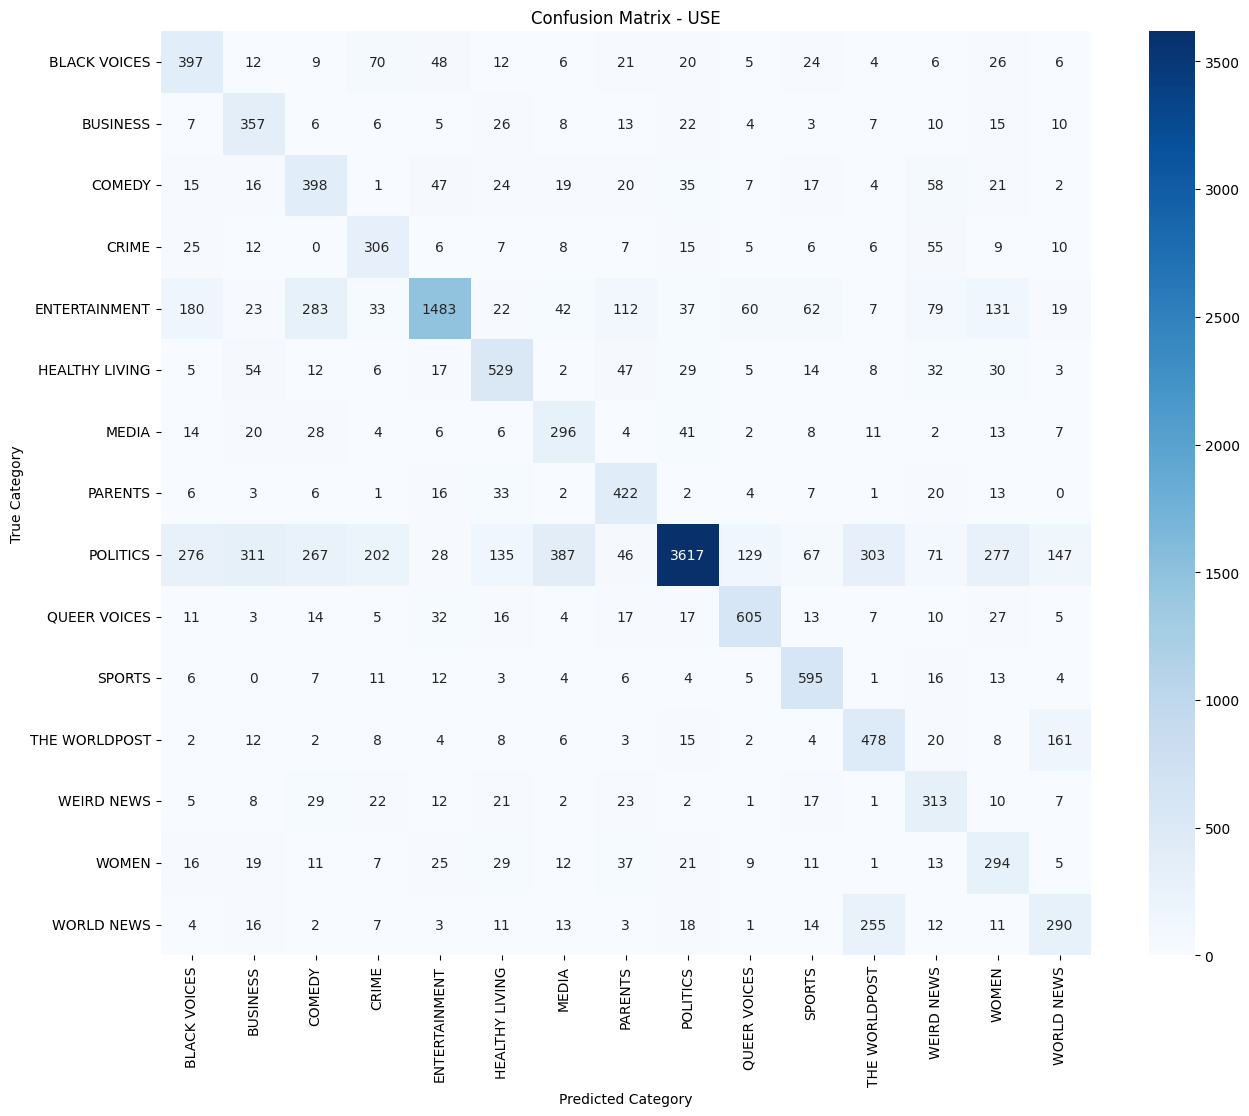

In [ ]:
def plot_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred, labels=np.arange(len(labels)))
    plt.figure(figsize=(15, 12))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel('Predicted Category')
    plt.ylabel('True Category')
    plt.show()

# Get class names for plotting
class_names = label_encoder.inverse_transform(np.arange(num_classes))

plot_confusion_matrix(y_test, y_pred_tfidf, class_names, 'Confusion Matrix - TF-IDF')
plot_confusion_matrix(y_test, y_pred_spacy_emb, class_names, 'Confusion Matrix - SpaCy Embeddings')
plot_confusion_matrix(y_test, y_pred_use_emb, class_names, 'Confusion Matrix - USE')

### Confusion Matrix Insights: How Well Do the Models Understand the Categories

After analyzing the confusion matrices from all three models (TF-IDF, SpaCy embeddings, and Universal Sentence Encoder (USE)), a few interesting patterns emerge.

**Categories That Are Often Mixed Up**

Some categories are consistently confused across all models:

- PARENTING vs PARENTS: These two are understandably tricky. They share similar language and themes, which leads to frequent misclassification between them, even with the USE model.

- STYLE & BEAUTY vs WELLNESS: These lifestyle-focused topics tend to overlap in content, making them harder for the models to distinguish.

- POLITICS vs BUSINESS or ENTERTAINMENT: Especially in the TF-IDF model, Politics sometimes gets confused with Business or Entertainment, likely due to shared news terms involving public figures or social events.

**Categories All Models Struggle With**

Some categories seem to be challenging for every model:

- PARENTS: This class often gets confused with PARENTING or even HOME & LIVING, possibly due to fewer examples or the similar tone used in articles.

- HEALTHY LIVING and FOOD & DRINK: These categories often cross over in content (e.g., diet tips, health trends), which makes it harder for the models to draw clear lines.

- BLACK VOICES and QUEER VOICES: Despite their distinct focus, the models sometimes mix them up, likely due to overlapping vocabulary related to social issues or community topics.

**Comparison of three models**

SpaCy embeddings do a better job than TF-IDF in some areas, especially where semantic meaning matters more than keyword frequency, but they still struggle with fine details.

USE clearly performs better overall. Since it captures sentence-level meaning, it reduces confusion in tricky cases like PARENTING vs PARENTS or STYLE & BEAUTY vs WELLNESS. It also tends to avoid overpredicting dominant classes like ENTERTAINMENT.

**In summary,**

While all models face challenges with closely related categories, USE stands out for its ability to understand context and separate similar topics more effectively. That said, no model is perfect, especially when categories naturally overlap or don’t have enough examples to learn from.

### Discussion and Findings

**Why Did TF-IDF Perform the Way It Did?**

TF-IDF performed reasonably well, especially in terms of accuracy. This makes sense because it works by highlighting the most important words in each article. For short texts like headlines and summaries, this can be effective, especially when certain keywords strongly signal a specific category.

However, TF-IDF doesn’t capture word meaning or context. For example, it treats “beauty tips” and “skincare advice” as unrelated even though they may fall under the same topic. This lack of semantic understanding often leads to confusion between similar categories, especially those with overlapping vocabulary.

**Why Did SpaCy Embeddings Perform the Way They Did?**

SpaCy’s word embeddings did a decent job by introducing semantic meaning into the representation. Since they are pre-trained on large corpora, they understand general relationships between words (e.g., “doctor” is related to “health”). This helped the model go beyond simple word matching.

However, because SpaCy uses static embeddings, every word has the same vector regardless of its context. The model simply averages the vectors in a sentence, which can dilute important meaning, especially in short texts where a single word can change the entire intent. This limits the model’s ability to fully capture subtle differences between similar categories.

**Why Did USE Perform the Way It Did?**

The Universal Sentence Encoder (USE) achieved the best overall performance across all metrics. Unlike the other methods, USE creates a single embedding for the entire sentence, capturing both context and semantics. This makes it particularly strong for short texts where context is crucial.

Its strength lies in understanding how words interact within a sentence, for example, it can differentiate between “parenting advice” and “parents react”, even though both mention “parents.” This context-aware understanding helped the model make more accurate predictions, especially for categories that are easily confused by keyword-based methods.

**Impact of Text Cleaning**

The SpaCy-based cleaning approach, which included lemmatization and part-of-speech filtering, helped reduce noise in the text (e.g., removing filler words and punctuation). Compared to the basic rule-based method, this approach retained more meaningful tokens and improved the quality of input for embedding models.

In particular, it seemed to benefit the SpaCy and USE models more than TF-IDF, since those rely more on semantic content. Better input meant clearer sentence-level meaning, which likely contributed to the overall performance gains.

**Class Imbalance and Its Impact**

Class imbalance was an issue in this dataset, categories like Politics had far more samples than others like Parents or Black Voices. This imbalance tends to inflate accuracy (since the model can guess the dominant class and still be "right") but lowers macro-averaged metrics like F1-score, which treat all classes equally.

To address this, I used class weights during training, so that underrepresented categories were not ignored. I also focused on macro-F1 as a key evaluation metric, since it gives a more balanced picture of the model’s true performance across all categories.

### Strengths & Weaknesses of Each Embedding Method

| **Embedding Method**   | **Strengths**                                                         | **Weaknesses**                                                  |
|------------------------|----------------------------------------------------------------------|------------------------------------------------------------------|
| **TF-IDF**             | Simple, fast, good for keyword-based classification                  | Can’t understand context or word meaning                        |
| **SpaCy Embeddings**   | Adds semantic meaning, better than TF-IDF in many cases              | Static word vectors limit sentence-level understanding          |
| **USE**                | Strong context and semantic awareness, best at fine-grained distinctions | Slightly heavier to compute, but worth it for the performance gain |




***Overall, USE proved to be the most effective embedding method for this task, especially in dealing with subtle category differences. That said, preprocessing choices, model architecture, and handling class imbalance all played important roles in shaping the final results.***


# Phase 7: Report -  News Categorization using Text Embeddings

## Introduction

The goal of this project is to build a text classification model that categorizes news articles into **news categories**, using a variety of word embedding techniques.

News categorization is important for multiple real-world applications, including **news organization**, **personalized content recommendations**, and **automated topic tracking** in journalism and media platforms.

In this project, I explore the full pipeline, from **text cleaning**, to **embedding methods**, to **model evaluation**, to compare how different representations affect model performance. I experiment with three embedding approaches: **TF-IDF**, **SpaCy Static Embeddings**, and **Universal Sentence Encoder (USE)**.

---

## Dataset Description

The dataset used is the **HuffPost News Category Dataset**, which includes over **200,000 news headlines and descriptions** published by HuffPost from 2012 to 2018.

- **Source**: Available publicly on Kaggle.
- **Structure**:
  - `category`: News topic label (e.g., POLITICS, WELLNESS, STYLE & BEAUTY).
  - `headline`: The title of the news article.
  - `short_description`: A brief summary of the article.
- For this project, I combined the `headline` and `short_description` fields into a single text field called `news_description` to give models richer context.
- I focused on the **top 15 most frequent categories** to keep the task balanced yet challenging.

---

## Exploratory Data Analysis

Several visualizations were used to understand the dataset:

- A **category distribution bar chart** showed a clear imbalance, with POLITICS dominating the dataset.
- A **histogram of description lengths** revealed that most articles are short, typically between 10 and 50 words.
- A **word cloud (before cleaning)** helped identify common noisy tokens like "one", "time", "make", and named entities that don’t always help in classification.

These insights guided both the preprocessing strategy and choice of evaluation metrics (e.g., macro-F1 to handle imbalance).

---

## Text  Cleaning & Preprocessing

### Why Cleaning Matters

Raw text often contains irrelevant tokens (e.g., links, punctuation, filler words) that can confuse models. Effective preprocessing helps highlight the meaningful content for downstream tasks.

### Approach 1: Basic Rule-Based Cleaning

Used regex operations to:
- Convert text to lowercase
- Remove URLs, punctuation, numbers, special characters
- Remove stopwords using NLTK
- Lemmatize words using `WordNetLemmatizer`

### Approach 2: SpaCy Pipeline-Based Cleaning

This approach used SpaCy’s powerful linguistic pipeline to process text at the token level. After converting the text to lowercase, I used SpaCy to remove punctuation, stopwords, and whitespace tokens. More importantly, I filtered by part-of-speech tags to retain only meaningful words such as **nouns, verbs, adjectives, and proper nouns**.

Lemmatization was also applied using SpaCy’s pre-trained models to reduce each word to its base form, helping reduce redundancy in the text. Compared to the basic rule-based approach, this method is more sophisticated and provides **cleaner, more semantically rich text** for downstream modeling.

---

### Final Cleaning Choice

Between the two cleaning approaches, I selected the **SpaCy-based method** for use in all model training. It was more effective at preserving meaningful context, especially when paired with semantic embedding techniques like SpaCy embeddings and USE.

---

## Embedding Methods & Model Architectures

### (1) TF-IDF

**TF-IDF (Term Frequency–Inverse Document Frequency)** is a statistical method that scores each word based on how important it is to a particular document relative to the entire corpus. It works well for keyword-based matching, which is suitable for short texts like headlines.

For this method, I limited the vocabulary to the top 5,000 most important unigrams and bigrams. The resulting TF-IDF vectors were used to train a simple feedforward neural network with two hidden layers and dropout regularization.

---

### (2) SpaCy Static Word Embeddings

This method uses SpaCy’s pre-trained word vectors from the `en_core_web_lg` model. These embeddings represent the semantic meaning of individual words but are **static**, meaning each word always has the same vector regardless of its context.

To represent an entire news article, I averaged the vectors of all meaningful tokens. This gave each article a fixed-length vector that reflects its general content. These embeddings were then passed into the same neural network architecture used for TF-IDF to ensure a fair comparison.

---

### (3) Universal Sentence Encoder (USE)

The Universal Sentence Encoder is a powerful pre-trained model from TensorFlow Hub. It produces a **single embedding vector for an entire sentence**, capturing context and semantics at the sentence level.

I used the USE model to embed each news description after preprocessing, and trained a neural network using these embeddings. This approach provided the most context-aware representation of the text and was especially effective for capturing subtle differences between similar categories.

---

## Results & Comparison

### Performance Summary Table

| Embedding Method     | Accuracy | F1-Macro | Precision-Macro | Recall-Macro |
|----------------------|----------|----------|------------------|---------------|
| TF-IDF               | 0.6816   | 0.6377   | 0.6269           | 0.6597        |
| SpaCy Embeddings     | 0.6592   | 0.6160   | 0.5967           | 0.6568        |
| Universal Sentence Encoder | **0.7110**   | **0.6599**   | **0.6465**           | **0.6944**        |

---

### Confusion Matrix Insights

By analyzing the confusion matrices of all three models, several patterns emerged:

- **PARENTING vs PARENTS** was frequently misclassified by all models, likely due to shared vocabulary and themes.
- **STYLE & BEAUTY vs WELLNESS** also showed considerable overlap, as both deal with lifestyle topics.
- **TF-IDF** was more prone to confusion between closely related categories due to its reliance on word counts.
- **SpaCy embeddings** offered some improvement by incorporating semantic meaning, but still struggled due to averaging.
- **USE** performed the best, showing clearer category separation and more accurate predictions across similar labels.

---

### Impact of Cleaning Strategies

The SpaCy-based cleaning approach helped produce more focused, meaningful text. This was particularly beneficial for the SpaCy and USE models, which rely on the semantic quality of the input. By removing filler words and emphasizing informative tokens, the preprocessing helped boost model clarity and generalization.

---

### Class Imbalance Consideration

The dataset was not balanced — categories like `POLITICS` had far more samples than others. This skewed the model’s predictions toward the most frequent categories.

To mitigate this, I:
- Used **class weights** during training so that rare categories still received attention.
- Focused on **macro-averaged metrics** like F1-score, precision, and recall, which give equal weight to all classes regardless of their frequency.

This helped create a more balanced evaluation of performance.

---

## Conclusion

This project explored three different embedding methods to tackle the task of fine-grained news categorization.

- **TF-IDF** performed reasonably well, especially for clear-cut categories, but struggled with semantic understanding.
- **SpaCy embeddings** improved semantic awareness but were limited by their static nature.
- **USE** outperformed both, thanks to its ability to capture sentence-level context and meaning.

This shows that **contextual embeddings like USE are particularly effective for short, fine-grained texts**, such as news headlines and summaries.

---

## Future Work

There are several areas where this project can be extended:

- Explore **transformer-based models** like BERT or DistilBERT fine-tuned on news data.
- Implement **active learning strategies** to better handle rare or underrepresented categories.
- Investigate **domain-specific embeddings** trained on news articles for more tailored performance.
- Add attention mechanisms to help models focus on the most relevant parts of each sentence.



## Export the trained model for the headline demo

The TF-IDF neural network is the recommended model for the first hosted demo because its inference dependencies are relatively lightweight. It uses the same TF-IDF + Dense neural-network approach as this notebook, trained on the uploaded dataset.

The exported files are:
- `news_category_tfidf.keras` — trained Keras classifier
- `tfidf_vectorizer.joblib` — fitted TF-IDF vocabulary and weights
- `label_encoder.joblib` — category ID ↔ category name mapping
- `model_metadata.json` — category list and test metrics

For prediction, the web API must apply the same basic text cleaning used in training, then TF-IDF transform and model prediction.

In [ ]:
import joblib
import json
import os

ARTIFACT_DIR = "news_category_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)

# Save the trained deployable model and its fitted preprocessing objects.
model_tfidf.save(os.path.join(ARTIFACT_DIR, "news_category_tfidf.keras"))
joblib.dump(
    tfidf_vectorizer,
    os.path.join(ARTIFACT_DIR, "tfidf_vectorizer.joblib")
)
joblib.dump(
    label_encoder,
    os.path.join(ARTIFACT_DIR, "label_encoder.joblib")
)

metadata = {
    "model_name": "TF-IDF + Dense Neural Network",
    "input_text": "headline (optionally combined with short description)",
    "categories": label_encoder.classes_.tolist(),
    "test_accuracy": float(accuracy_tfidf),
    "test_macro_f1": float(f1_tfidf),
    "max_features": 5000,
    "ngram_range": [1, 2],
    "cleaning": "basic lowercasing, URL/email/hashtag/punctuation/number removal, English stopword removal, WordNet lemmatization"
}
with open(os.path.join(ARTIFACT_DIR, "model_metadata.json"), "w") as f:
    json.dump(metadata, f, indent=2)

# Zip the files so they can be downloaded and added to your deployment repository.
import shutil
shutil.make_archive("news_category_artifacts", "zip", ARTIFACT_DIR)

print("Saved deployment artifacts:")
print(os.listdir(ARTIFACT_DIR))
print("Created news_category_artifacts.zip")


Saved deployment artifacts:
['news_category_tfidf.keras', 'model_metadata.json', 'tfidf_vectorizer.joblib', 'label_encoder.joblib']
Created news_category_artifacts.zip


## Test a headline (same preprocessing as the hosted demo)

Try a headline that was not part of the training examples. The model returns its most likely category and confidence scores.

In [ ]:
def clean_headline_for_prediction(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'\S*@\S*\s?', '', text)
    text = re.sub(r'#\S+', '', text)
    text = re.sub(r'[^\w\s]', '', text)
    text = re.sub(r'\d+', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    return " ".join(tokens)

def predict_news_category(headline, top_k=3):
    cleaned = clean_headline_for_prediction(headline)
    features = tfidf_vectorizer.transform([cleaned]).toarray().astype(np.float32)
    probabilities = model_tfidf.predict(features, verbose=0)[0]
    top_indices = np.argsort(probabilities)[::-1][:top_k]
    return pd.DataFrame({
        "category": label_encoder.inverse_transform(top_indices),
        "confidence": probabilities[top_indices]
    })

# Change this example headline to test your own.
test_headline = "Central bank announces a new policy to control inflation"
display(predict_news_category(test_headline))


,category,confidence
0,BUSINESS,0.893366
1,THE WORLDPOST,0.030963
2,WORLD NEWS,0.027000


In [ ]:
from google.colab import files

files.download("news_category_artifacts.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>